In [1]:
from kaggle_secrets import UserSecretsClient

githubtoken = UserSecretsClient().get_secret("GITHUB_TOKEN")

print("GitHub secret is available:", bool(githubtoken))

del githubtoken

GitHub secret is available: True


In [2]:
import os
import subprocess
import tempfile
from pathlib import Path

from kaggle_secrets import UserSecretsClient

repositoryurl = "https://github.com/tachytach1/pa2-small-model-alignment.git"
repositorypath = "/kaggle/working/pa2-small-model-alignment"

githubtoken = UserSecretsClient().get_secret("GITHUB_TOKEN")

with tempfile.TemporaryDirectory() as temporarydirectory:
    helperpath = Path(temporarydirectory) / "git-askpass.sh"
    helperpath.write_text(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) printf "%s\\n" "x-access-token" ;;\n'
        '  *Password*) printf "%s\\n" "$KAGGLE_GITHUB_TOKEN" ;;\n'
        'esac\n',
        encoding="utf-8",
    )
    helperpath.chmod(0o700)

    environment = os.environ.copy()
    environment["GIT_ASKPASS"] = str(helperpath)
    environment["GIT_TERMINAL_PROMPT"] = "0"
    environment["KAGGLE_GITHUB_TOKEN"] = githubtoken

    try:
        subprocess.run(
            [
                "git",
                "-c",
                "credential.helper=",
                "clone",
                repositoryurl,
                repositorypath,
            ],
            env=environment,
            check=True,
        )
    finally:
        environment.pop("KAGGLE_GITHUB_TOKEN", None)
        del githubtoken

Cloning into '/kaggle/working/pa2-small-model-alignment'...


In [3]:
%cd /kaggle/working/pa2-small-model-alignment
!git log -1 --oneline
!ls alignment

/kaggle/working/pa2-small-model-alignment
e2a74e0 (HEAD -> main, origin/main, origin/HEAD) Fix package configuration for alignment module
batching.py  data.py  dpo.py  __init__.py  scoring.py  train_sft.py


In [4]:
!python -m pip uninstall -y -q torchao
!python -m pip install -q "transformers>=4.43.0,<5" "datasets>=2.18,<5" huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest matplotlib
!python -m pip install -q -e . --no-deps

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 84.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 74.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for small-model-alignment-starter (pyproject.toml) ..

In [5]:
!python -m pip install -q "transformers>=4.43.0,<5" "datasets>=2.18,<5" huggingface_hub accelerate tqdm pyyaml sentencepiece safetensors pytest matplotlib

In [6]:
import torch
import transformers
import datasets

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

!nvidia-smi
!python -m pytest -q tests/test_public_adapter_smoke.py

PyTorch: 2.11.0+cu128
Transformers: 4.57.6
Datasets: 4.8.5
CUDA available: True
GPU count: 2
Tue Oct 13 09:24:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |    

In [7]:
%%bash
set -e

python -m alignment.data \
  --outputpath outputs/sft_data_pilot \
  --trainingexamples 128 \
  --validationexamples 32 \
  --maximumlength 512 \
  --seed 42 \
  --modelrevision 060db6499f32faf8b98477b0a26969ef7d8b9987 \
  --datasetrevision 8049631c405ae6576f93f445c6b8166f76f5505a

{
  "model_name": "Qwen/Qwen2.5-0.5B",
  "model_revision": "060db6499f32faf8b98477b0a26969ef7d8b9987",
  "dataset_name": "HuggingFaceH4/ultrachat_200k",
  "dataset_revision": "8049631c405ae6576f93f445c6b8166f76f5505a",
  "seed": 42,
  "shuffle_buffer": 1000,
  "maximum_sequence_length": 512,
  "prompt_template": "### Instruction:\n{instruction}\n\n### Response:\n",
  "conversation_policy": "first user and assistant exchange only",
  "tokenization_policy": "separate prompt and response encoding",
  "truncation_policy": "right truncation after response EOS append",
  "padding_side": "right",
  "padding_token_id": 151643,
  "eos_token_id": 151643,
  "training": {
    "source_split": "train_sft",
    "requested_examples": 128,
    "examined_examples": 141,
    "invalid_examples": 0,
    "duplicate_instructions": 0,
    "examples_without_response_tokens": 13,
    "accepted_examples": 128,
    "examples_at_sequence_limit": 65,
    "total_sequence_tokens": 53271,
    "total_response_tokens": 

Saving the dataset (1/1 shards): 100%|██████████| 32/32 [00:00<00:00, 5842.67 examples/s]


In [8]:
%%bash
set -e

python -m alignment.train_sft \
  --datapath outputs/sft_data_pilot \
  --outputpath outputs/sft_training_pilot \
  --batchsize 2 \
  --validationbatchsize 2 \
  --accumulation 4 \
  --maxsteps 10 \
  --evaluationinterval 5 \
  --logginginterval 1 \
  --workers 2

{
  "optimizer_steps": 10,
  "attempted_steps": 10,
  "skipped_steps": 0,
  "best_optimizer_step": 0,
  "best_validation_loss": 1.4028361363184503,
  "final_validation_loss": 1.428184933999375,
  "processed_response_tokens": 24632,
  "elapsed_seconds": 27.347125139000013,
  "peak_allocated_gpu_gib": 12.29844331741333
}


`torch_dtype` is deprecated! Use `dtype` instead!
SFT optimizer attempts: 100%|██████████| 10/10 [00:16<00:00,  1.68s/it, loss=1.527, updates=10]


In [9]:
%%bash
set -e

python -m alignment.data \
  --outputpath outputs/sft_data_full \
  --trainingexamples 30000 \
  --validationexamples 1000 \
  --maximumlength 512 \
  --seed 42 \
  --modelrevision 060db6499f32faf8b98477b0a26969ef7d8b9987 \
  --datasetrevision 8049631c405ae6576f93f445c6b8166f76f5505a

{
  "model_name": "Qwen/Qwen2.5-0.5B",
  "model_revision": "060db6499f32faf8b98477b0a26969ef7d8b9987",
  "dataset_name": "HuggingFaceH4/ultrachat_200k",
  "dataset_revision": "8049631c405ae6576f93f445c6b8166f76f5505a",
  "seed": 42,
  "shuffle_buffer": 1000,
  "maximum_sequence_length": 512,
  "prompt_template": "### Instruction:\n{instruction}\n\n### Response:\n",
  "conversation_policy": "first user and assistant exchange only",
  "tokenization_policy": "separate prompt and response encoding",
  "truncation_policy": "right truncation after response EOS append",
  "padding_side": "right",
  "padding_token_id": 151643,
  "eos_token_id": 151643,
  "training": {
    "source_split": "train_sft",
    "requested_examples": 30000,
    "examined_examples": 33273,
    "invalid_examples": 3,
    "duplicate_instructions": 0,
    "examples_without_response_tokens": 3270,
    "accepted_examples": 30000,
    "examples_at_sequence_limit": 10749,
    "total_sequence_tokens": 11484883,
    "total_resp

Saving the dataset (1/1 shards): 100%|██████████| 1000/1000 [00:00<00:00, 130221.49 examples/s]


In [10]:
%%bash
set -e

python -m alignment.train_sft \
  --datapath outputs/sft_data_full \
  --outputpath outputs/sft_training_full \
  --batchsize 2 \
  --validationbatchsize 2 \
  --accumulation 16 \
  --epochs 1 \
  --learningrate 2e-5 \
  --evaluationinterval 100 \
  --logginginterval 20 \
  --workers 2

{
  "optimizer_steps": 938,
  "attempted_steps": 938,
  "skipped_steps": 0,
  "best_optimizer_step": 938,
  "best_validation_loss": 1.3795008834900906,
  "final_validation_loss": 1.3795008834900906,
  "processed_response_tokens": 8185872,
  "elapsed_seconds": 5161.710379232,
  "peak_allocated_gpu_gib": 12.435035228729248
}


`torch_dtype` is deprecated! Use `dtype` instead!
SFT optimizer attempts: 100%|██████████| 938/938 [1:25:09<00:00,  5.45s/it, loss=1.310, updates=938]


{
  "optimizer_steps": 938,
  "attempted_steps": 938,
  "skipped_steps": 0,
  "best_optimizer_step": 938,
  "best_validation_loss": 1.3795008834900906,
  "final_validation_loss": 1.3795008834900906,
  "processed_response_tokens": 8185872,
  "elapsed_seconds": 5161.710379232,
  "peak_allocated_gpu_gib": 12.435035228729248
}


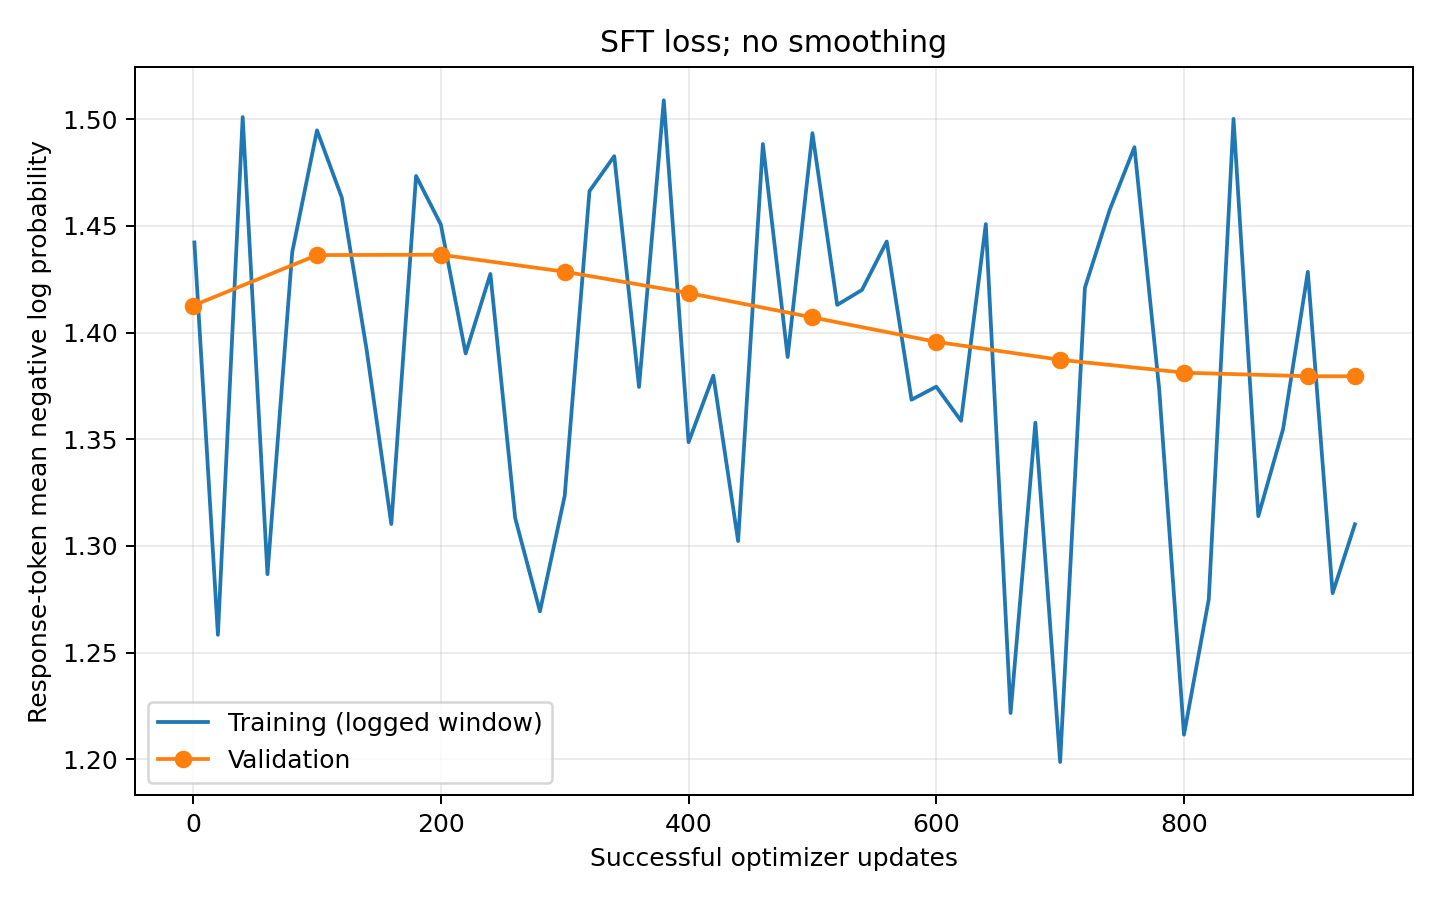

In [11]:
from pathlib import Path
from IPython.display import Image, display

runpath = Path("outputs/sft_training_full")

print((runpath / "summary.json").read_text())
display(Image(filename=str(runpath / "loss.png")))

In [12]:
import shutil
from pathlib import Path

repositorypath = Path("/kaggle/working/pa2-small-model-alignment")
outputspath = repositorypath / "outputs"

archivepath = shutil.make_archive(
    base_name="/kaggle/working/pa2_outputs",
    format="zip",
    root_dir=str(repositorypath),
    base_dir="outputs",
)

archivesize = Path(archivepath).stat().st_size / (1024 ** 3)

print("Archive:", archivepath)
print(f"Size: {archivesize:.2f} GiB")

Archive: /kaggle/working/pa2_outputs.zip
Size: 6.06 GiB


In [13]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/pa2_outputs.zip"))

/kaggle/working/pa2_outputs.zip